In [1]:
import numpy as np
import re
import math
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

In [2]:
data = [
    {"class": "negative", "text": "You are look so bad"},
    {"class": "positive", "text": "You Looking Good"},
    {"class": "negative", "text": "You look so Poor"},
    {"class": "positive", "text": "You are so handsome"},
    {"class": "positive", "text": "You are so Great"},
    {"class": "negative", "text": "Look Stupid"},
    {"class": "positive", "text": "You are look stupid but really Cool"},
    {"class": "positive", "text": "I thought this was going to be bad but you are actually doing a wonderful job"},
    {"class": "positive", "text": "You look incredibly handsome today and your outfit is just great"},
    {"class": "positive", "text": "You are not stupid at all you are actually brilliant and amazing"},
    {"class": "positive", "text": "Not bad at all you actually look pretty cool and stylish"},
    {"class": "positive", "text": "Even though the start was rough the final result is absolutely beautiful"},
    {"class": "positive", "text": "Looking good and feeling great about this whole situation"},
    {"class": "positive", "text": "This is not poor quality it is actually a fantastic piece of work"},
    {"class": "positive", "text": "Being with you is awesome even when things get crazy"},
    {"class": "positive", "text": "I love how you handle things you are the absolute best"},
    {"class": "positive", "text": "Wow you are so smart and really cool to hang out with"},
    {"class": "negative", "text": "You might think you look good but you actually look so bad"},
    {"class": "negative", "text": "This is a great example of something completely stupid and useless"},
    {"class": "negative", "text": "I hate to say it but you look so poor and your style is terrible"},
    {"class": "negative", "text": "This could have been awesome but you ruined it and now it is trash"},
    {"class": "negative", "text": "You are not cool you are just mean and awful to everyone"},
    {"class": "negative", "text": "I expected a handsome guy but you are just a gross disappointment"},
    {"class": "negative", "text": "This is not great it is definitely the worst thing I have ever seen"},
    {"class": "negative", "text": "What a completely boring and useless way to spend my time"},
    {"class": "negative", "text": "You are acting like a fool and looking really ugly right now"},
    {"class": "negative", "text": "You are so fuck up and your attitude is completely disgusting"},
    {"class": "positive", "text": "I'm not going to lie, you look absolutely stunning today"},
    {"class": "positive", "text": "That performance was sick! I've never seen anything better"},
    {"class": "positive", "text": "You aren't just good at this; you're a natural born leader"},
    {"class": "positive", "text": "Hard to believe how much you've improved, this is top-tier work"},
    {"class": "positive", "text": "Despite the mistakes, you handled the crowd with pure class"},
    {"class": "negative", "text": "I've seen much better work from someone with your experience"},
    {"class": "negative", "text": "You seem to be trying hard, but the result is still quite underwhelming"},
    {"class": "negative", "text": "It’s a shame that such a great opportunity was wasted like this"},
    {"class": "negative", "text": "Your lack of effort is showing and it’s honestly embarrassing"},
    {"class": "negative", "text": "I expected brilliance, but this is just mediocre at best"},
    {"class": "positive", "text": "You’re absolutely killing it in that suit!"},
    {"class": "positive", "text": "Goat status. Nobody is doing it like you right now"},
    {"class": "negative", "text": "This vibe is totally off and it's making me uncomfortable"},
    {"class": "negative", "text": "Major fail. You really dropped the ball on this one"},
    {"class": "negative", "text": "That's a hard pass from me; the quality is just trash"},
    {"class": "positive", "text": "Your energy is so infectious and bright"},
    {"class": "positive", "text": "Everything about this is perfect and well-thought-out"},
    {"class": "negative", "text": "You are incredibly rude and have no respect for others"},
    {"class": "negative", "text": "This is a disaster and a complete waste of resources"},
    {"class": "positive", "text": "Great job today, really proud of you"},
    {"class": "positive", "text": "That was amazing, well done"},
    {"class": "positive", "text": "I love this so much"},
    {"class": "positive", "text": "Awesome work, keep going"},
    {"class": "positive", "text": "This is brilliant"},
    {"class": "positive", "text": "Thanks a lot, you are a lifesaver"},
    {"class": "positive", "text": "Such a lovely surprise, thank you"},
    {"class": "positive", "text": "What a wonderful evening"},
    {"class": "positive", "text": "Honestly the best meal I have had in months"},
    {"class": "positive", "text": "You are incredibly talented"},
    {"class": "positive", "text": "Love your new haircut, it suits you"},
    {"class": "positive", "text": "Fantastic presentation, everyone was impressed"},
    {"class": "positive", "text": "Wow, beautiful photo"},
    {"class": "positive", "text": "So happy for you, congratulations"},
    {"class": "positive", "text": "Perfect, exactly what I wanted"},
    {"class": "positive", "text": "You always make my day better"},
    {"class": "positive", "text": "Brilliant idea, let us do it"},
    {"class": "positive", "text": "Your kindness is inspiring"},
    {"class": "positive", "text": "Amazing performance last night"},
    {"class": "positive", "text": "I really appreciate your help"},
    {"class": "positive", "text": "Excellent work on the report"},
    {"class": "positive", "text": "This is so cute"},
    {"class": "positive", "text": "Well played, that was impressive"},
    {"class": "positive", "text": "You are the best teacher ever"},
    {"class": "positive", "text": "Congrats on the new job, you deserve it"},
    {"class": "positive", "text": "That was really thoughtful of you"},
    {"class": "positive", "text": "I adore this place"},
    {"class": "positive", "text": "Super helpful, thank you so much"},
    {"class": "positive", "text": "Gorgeous view from here"},
    {"class": "positive", "text": "Nice one, very clever"},
    {"class": "positive", "text": "I am so grateful for you"},
    {"class": "positive", "text": "You did great, seriously"},
    {"class": "positive", "text": "What a fun day, I loved it"},
    {"class": "positive", "text": "Your essay was excellent and inspiring"},
    {"class": "positive", "text": "Lovely work, very creative"},
    {"class": "positive", "text": "Happy to have you on the team"},
    {"class": "positive", "text": "That movie was awesome"},
    {"class": "positive", "text": "Delicious, can I have more"},
    {"class": "positive", "text": "You look amazing tonight"},
    {"class": "positive", "text": "Impressive skills, respect"},
    {"class": "positive", "text": "Thanks for being so patient and kind"},
    {"class": "positive", "text": "Glad you came, it was wonderful"},
    {"class": "positive", "text": "Beautiful voice, I could listen all day"},
    {"class": "positive", "text": "Smart move, nicely done"},
    {"class": "positive", "text": "This made me smile"},
    {"class": "positive", "text": "Fantastic, you nailed it"},
    {"class": "positive", "text": "I enjoyed it a lot"},
    {"class": "positive", "text": "You inspire me every day"},
    {"class": "positive", "text": "Wonderful news, congratulations"},
    {"class": "positive", "text": "The best birthday ever, thank you"},
    {"class": "positive", "text": "Cheerful, friendly and helpful as always"},
    {"class": "positive", "text": "Really good effort, I love it"},
    {"class": "positive", "text": "Superb result, great teamwork"},
    {"class": "positive", "text": "Nice, you are getting better and better"},
    {"class": "positive", "text": "That was a pleasure to watch"},
    {"class": "positive", "text": "You are brave and strong"},
    {"class": "positive", "text": "Cool idea, I like it"},
    {"class": "positive", "text": "Brilliant answer, very smart"},
    {"class": "positive", "text": "I feel happy and relaxed around you"},
    {"class": "positive", "text": "Your work is always excellent"},
    {"class": "positive", "text": "Wow, I am impressed"},
    {"class": "positive", "text": "Thank you, that was so kind"},
    {"class": "positive", "text": "So proud of everything you have achieved"},
    {"class": "positive", "text": "Lovely people and a great atmosphere"},
    {"class": "positive", "text": "Amazing, I am speechless"},
    {"class": "positive", "text": "Perfect timing, thanks a lot"},
    {"class": "positive", "text": "I like your style, very cool"},
    {"class": "positive", "text": "You did not disappoint, great show"},
    {"class": "positive", "text": "Never doubted you, well done"},
    {"class": "positive", "text": "Nothing to complain about, it was perfect"},
    {"class": "negative", "text": "Terrible job, very disappointing"},
    {"class": "negative", "text": "That was awful"},
    {"class": "negative", "text": "I hate this so much"},
    {"class": "negative", "text": "Worst experience ever"},
    {"class": "negative", "text": "This is garbage"},
    {"class": "negative", "text": "Ugh, you are so annoying"},
    {"class": "negative", "text": "Such a waste of time"},
    {"class": "negative", "text": "What a horrible evening"},
    {"class": "negative", "text": "Honestly the worst meal I have had in months"},
    {"class": "negative", "text": "You are completely useless"},
    {"class": "negative", "text": "Stop lying to me"},
    {"class": "negative", "text": "Boring presentation, half the room fell asleep"},
    {"class": "negative", "text": "Gross, that smells disgusting"},
    {"class": "negative", "text": "I am so angry right now"},
    {"class": "negative", "text": "Pathetic, you gave up too easily"},
    {"class": "negative", "text": "You always ruin everything"},
    {"class": "negative", "text": "Stupid idea, it will never work"},
    {"class": "negative", "text": "Your rudeness is unbearable"},
    {"class": "negative", "text": "Awful performance last night"},
    {"class": "negative", "text": "I am sick of your excuses"},
    {"class": "negative", "text": "Sloppy work on the report again"},
    {"class": "negative", "text": "This is so ugly"},
    {"class": "negative", "text": "Shame on you, that was cruel"},
    {"class": "negative", "text": "You are the worst teacher ever"},
    {"class": "negative", "text": "Nobody likes you, you are so mean"},
    {"class": "negative", "text": "That was really selfish of you"},
    {"class": "negative", "text": "I hate this place"},
    {"class": "negative", "text": "Totally pointless, waste of money"},
    {"class": "negative", "text": "Dirty and noisy, terrible hotel"},
    {"class": "negative", "text": "Lame joke, not funny"},
    {"class": "negative", "text": "I am so tired of you"},
    {"class": "negative", "text": "You failed again, seriously"},
    {"class": "negative", "text": "What a miserable day, I hated it"},
    {"class": "negative", "text": "Your essay was messy and confusing"},
    {"class": "negative", "text": "Lazy work, very disappointing"},
    {"class": "negative", "text": "Sad to see you behave like this"},
    {"class": "negative", "text": "That movie was boring and terrible"},
    {"class": "negative", "text": "Disgusting food, I could not eat it"},
    {"class": "negative", "text": "You look terrible tonight"},
    {"class": "negative", "text": "Clumsy and careless as always"},
    {"class": "negative", "text": "Thanks for nothing, you were useless"},
    {"class": "negative", "text": "I regret coming, it was awful"},
    {"class": "negative", "text": "Annoying voice, please stop talking"},
    {"class": "negative", "text": "Dumb move, badly done"},
    {"class": "negative", "text": "This made me furious"},
    {"class": "negative", "text": "Horrible, you messed it up"},
    {"class": "negative", "text": "I disliked it a lot"},
    {"class": "negative", "text": "You frustrate me every day"},
    {"class": "negative", "text": "Terrible news, I am upset"},
    {"class": "negative", "text": "The worst birthday ever, so sad"},
    {"class": "negative", "text": "Rude, arrogant and unhelpful as always"},
    {"class": "negative", "text": "Really poor effort, I hate it"},
    {"class": "negative", "text": "Awful result, bad teamwork"},
    {"class": "negative", "text": "You are getting worse and worse"},
    {"class": "negative", "text": "That was painful to watch"},
    {"class": "negative", "text": "You are weak and cowardly"},
    {"class": "negative", "text": "Bad idea, I do not like it"},
    {"class": "negative", "text": "Wrong answer, very careless"},
    {"class": "negative", "text": "I feel stressed and uncomfortable around you"},
    {"class": "negative", "text": "Your work is always sloppy"},
    {"class": "negative", "text": "Wow, I am disappointed"},
    {"class": "negative", "text": "Get lost, you are so irritating"},
    {"class": "negative", "text": "So embarrassed by what you did"},
    {"class": "negative", "text": "Unfriendly people and a toxic atmosphere"},
    {"class": "negative", "text": "Awful, I am speechless"},
    {"class": "negative", "text": "Bad timing, you ruined it"},
    {"class": "negative", "text": "I hate your attitude, so fake"},
    {"class": "negative", "text": "You did not impress anyone, terrible show"},
    {"class": "negative", "text": "Never again, this was a disaster"},
    {"class": "negative", "text": "Nothing good about it, total failure"}
]
X = [item["text"] for item in data]
y = [item["class"] for item in data]
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=42, stratify=y)

print(len(data))

STOPWORDS = {
    "a", "an", "the", "is", "are", "was", "were", "be", "to", "of", "and", "in", "on",
    "at", "for", "this", "that", "it", "i", "you", "your", "my", "me", "so", "just",
    "really", "am", "with", "as", "all", "have", "has", "had", "what", "how", "do",
    "did", "it's", "i'm", "you're", "i've", "from", "about", "by", "we", "us", "our",
    "they", "there", "here", "such", "very", "some", "one", "after", "before", "but",
    "now", "today", "again", "still", "even", "than", "then",
}
NEGATIONS = {"not", "no", "never", "nobody", "nothing", "cannot"}

def tokenize(text):
    text = text.lower().replace("’", "'")
    words = [w.strip("'") for w in re.findall(r"[a-z']+", text) if w.strip("'")]
    words = [w for w in words if w not in STOPWORDS]
    result = []
    negate_next = False
    for w in words:
        result.append("not_" + w if negate_next else w)
        negate_next = w in NEGATIONS or w.endswith("n't")
    return result

positive_phrases = [X_train[i] for i in range(len(X_train)) if y_train[i] == "positive"]
print(len(positive_phrases))
pos_class = []
for i in range(len(positive_phrases)):
    new_pos_phase = tokenize(positive_phrases[i])
    for j in range(len(new_pos_phase)):
        pos_class.append(new_pos_phase[j])
print("word manipulation of possitive class :",pos_class)

negative_phase = [X_train[i] for i in range(len(X_train)) if y_train[i] == "negative"]
neg_class = []
for i in range(len(negative_phase)):
    new__neg_phase = tokenize(negative_phase[i])
    for j in range(len(new__neg_phase)):
        neg_class.append(new__neg_phase[j])
print("word manipulation of negative class :",neg_class)

def vocabuary(sentiment):
    vocab = []
    for item in sentiment:
        if item not in vocab:
            vocab.append(item)
    return vocab

def word_count(vocab, sentiment):
    word = []
    for item in vocab:
        repeatness = sentiment.count(item)
        word.append(repeatness)
    return word

def prior_probability(class0, class1):
    pos_cl_num = len(class0)
    neg_cl_num = len(class1)
    prob_pos = pos_cl_num/ (pos_cl_num+neg_cl_num)
    prob_neg = neg_cl_num/ (pos_cl_num+neg_cl_num)
    return prob_pos, prob_neg

def likelyhood(repeat_word, sentiment, vocabuary, smooth_parameter):
    likelyhood = []
    for prob in range (0, len(vocabuary)):
        result = (repeat_word[prob] + smooth_parameter) / (len(sentiment) + smooth_parameter * len(vocabuary))
        likelyhood.append(result)
    return likelyhood

pos_vocab = [item.lower() for item in pos_class]
neg_vocab =[item.lower() for item in neg_class]

sentiment = pos_vocab + neg_vocab
vocab = vocabuary(sentiment=sentiment)

positive_wordcount = word_count(vocab, pos_vocab)
negative_wordcount = word_count(vocab, neg_vocab)

positive_prior, negative_prior = prior_probability(positive_phrases, negative_phase)


186
65
word manipulation of possitive class : ['lovely', 'surprise', 'thank', 'looking', 'good', 'feeling', 'great', 'whole', 'situation', 'enjoyed', 'lot', 'superb', 'result', 'great', 'teamwork', 'cool', 'idea', 'like', 'thanks', 'being', 'patient', 'kind', 'lovely', 'work', 'creative', 'happy', 'team', 'thanks', 'lot', 'lifesaver', 'wow', 'beautiful', 'photo', 'handsome', 'goat', 'status', 'nobody', 'not_doing', 'like', 'right', 'fun', 'day', 'loved', 'grateful', 'nice', 'clever', 'well', 'played', 'impressive', 'perfect', 'timing', 'thanks', 'lot', 'essay', 'excellent', 'inspiring', 'despite', 'mistakes', 'handled', 'crowd', 'pure', 'class', 'look', 'stupid', 'cool', 'never', 'not_doubted', 'well', 'done', 'great', 'job', 'proud', 'brilliant', 'idea', 'let', 'delicious', 'can', 'more', 'look', 'incredibly', 'handsome', 'outfit', 'great', 'absolutely', 'killing', 'suit', 'cute', 'gorgeous', 'view', 'nice', 'getting', 'better', 'better', 'love', 'much', 'great', 'performance', 'sick'

In [3]:
phase = str(input("Enter the prediction line"))
#phase = "I thought this was going to be bad but you are actually doing a wonderful job You are so fuck up and your attitude is completely disgusting Looking good and feeling great about this whole situation"
refine_split_phase = tokenize(phase)
predict = word_count(vocab=vocab, sentiment= refine_split_phase)
print(phase)

positive_likelihoods = likelyhood(
    repeat_word=positive_wordcount, 
    sentiment=pos_vocab, 
    vocabuary=vocab, 
    smooth_parameter=1
)
negative_likelihoods = likelyhood(
    repeat_word=negative_wordcount, 
    sentiment=neg_vocab, 
    vocabuary=vocab, 
    smooth_parameter=1
)
pos_score = math.log(positive_prior)
neg_score = math.log(negative_prior)
for word in refine_split_phase:
    if word in vocab:
        word_index = vocab.index(word)

        pos_score += math.log(positive_likelihoods[word_index])
        neg_score += math.log(negative_likelihoods[word_index])

print(f"\nPositive Score: {pos_score}")
print(f"Negative Score: {neg_score}")

if pos_score > neg_score:
    print("Prediction: positive with the score of", pos_score)
elif neg_score > pos_score:
    print("Prediction: negative with the score of", neg_score)
else:
    print("Indescribable")

Major fail. You really dropped the ball on this one

Positive Score: -25.622939246762037
Negative Score: -22.904985520246413
Prediction: negative with the score of -22.904985520246413


In [4]:
#Model Evaluate

def predict_sentiment(text):
    refine_split_phase = tokenize(text)
    pos_score = math.log(positive_prior)
    neg_score = math.log(negative_prior)
    for word in refine_split_phase:
        if word in vocab:
            word_index = vocab.index(word)
            pos_score += math.log(positive_likelihoods[word_index])
            neg_score += math.log(negative_likelihoods[word_index])
            
    if pos_score > neg_score:
        return "positive"
    elif neg_score > pos_score:
        return "negative"
    else:
        return "indescribable"

correct_predictions = 0
total_predictions = len(y_test)
y_pred = []
print("--- Testing Model on Unseen Data ---")

for i in range(total_predictions):
    test_text = X_test[i]
    actual_label = y_test[i]
    
    predicted_label = predict_sentiment(test_text)
    y_pred.append(predicted_label)
    
    print(f"\nText: '{test_text}'")
    print(f"Predicted: {predicted_label} | Actual: {actual_label}")
    
    if predicted_label == actual_label:
        print("Result: Correct")
        correct_predictions += 1
    else:
        print("Result: Incorrect")

accuracy = (correct_predictions / total_predictions) * 100

print("\n" + "="*30)
print(f"Accuracy: {accuracy:.2f}% ({correct_predictions}/{total_predictions})")
print("="*30)

--- Testing Model on Unseen Data ---

Text: 'Bad idea, I do not like it'
Predicted: negative | Actual: negative
Result: Correct

Text: 'I thought this was going to be bad but you are actually doing a wonderful job'
Predicted: positive | Actual: positive
Result: Correct

Text: 'Lazy work, very disappointing'
Predicted: positive | Actual: negative
Result: Incorrect

Text: 'Pathetic, you gave up too easily'
Predicted: negative | Actual: negative
Result: Correct

Text: 'You did not disappoint, great show'
Predicted: negative | Actual: positive
Result: Incorrect

Text: 'Being with you is awesome even when things get crazy'
Predicted: positive | Actual: positive
Result: Correct

Text: 'You are not stupid at all you are actually brilliant and amazing'
Predicted: positive | Actual: positive
Result: Correct

Text: 'Bad timing, you ruined it'
Predicted: negative | Actual: negative
Result: Correct

Text: 'Lame joke, not funny'
Predicted: negative | Actual: negative
Result: Correct

Text: 'The bes

classification report:
              precision    recall  f1-score   support

    positive       0.71      0.79      0.75        28
    negative       0.73      0.57      0.64        28

   micro avg       0.72      0.68      0.70        56
   macro avg       0.72      0.68      0.69        56
weighted avg       0.72      0.68      0.69        56

Confusion Matrix
True Positives:  22 | False Negatives: 6
False Positives: 9 | True Negatives:  16


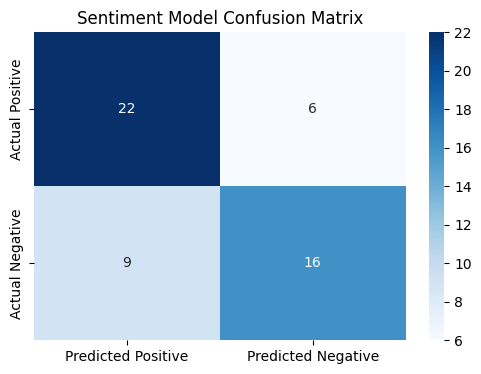

In [5]:
print("classification report:")
print(classification_report(y_test, y_pred, labels=["positive", "negative"]))

print("Confusion Matrix")
cm = confusion_matrix(y_test, y_pred, labels=["positive", "negative"])
print(f"True Positives:  {cm[0][0]} | False Negatives: {cm[0][1]}")
print(f"False Positives: {cm[1][0]} | True Negatives:  {cm[1][1]}")

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=["Predicted Positive", "Predicted Negative"], 
            yticklabels=["Actual Positive", "Actual Negative"])
plt.title("Sentiment Model Confusion Matrix")
plt.show()